In [7]:
from pathlib import Path
import pandas as pd
import numpy as np

# Correct dataset path
data_path = (
    Path.cwd()
    / "Dataset"
    / "online+retail"
    / "Online Retail.xlsx"
)

print("File exists:", data_path.exists())

# Load dataset
df = pd.read_excel(data_path)

print("\nDataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

File exists: True

Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
# Step 5: Initial Data Quality Check

print("=" * 50)
print("DATASET OVERVIEW")
print("=" * 50)

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values by column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().T)

print("\nFirst 5 rows:")
display(df.head())

DATASET OVERVIEW
Total rows: 541909
Total columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Missing values by column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total missing values: 136534

Duplicate rows: 5268

Numerical summary:


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303



First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
# Step 6: Detailed Data Quality Investigation

# Missing values report
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_report)

# Duplicate records
print("Total duplicate rows:", df.duplicated().sum())

# Check whether descriptions and customer IDs are missing
print("\nMissing Description:", df["Description"].isnull().sum())
print("Missing CustomerID:", df["CustomerID"].isnull().sum())

,Missing_Count,Missing_Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


Total duplicate rows: 5268

Missing Description: 1454
Missing CustomerID: 135080


In [10]:
# Step 7: Investigate Duplicate Records

# Find all rows that are exact duplicates
duplicate_rows = df[df.duplicated(keep=False)]

print("Total rows marked as duplicates:", len(duplicate_rows))

print("\nFirst 10 duplicate rows:")
display(duplicate_rows.head(10))

# Count duplicate rows excluding the first occurrence
print("\nDuplicate rows excluding first occurrence:", df.duplicated().sum())

Total rows marked as duplicates: 10147

First 10 duplicate rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom



Duplicate rows excluding first occurrence: 5268


In [11]:
# Step 8: Investigate Missing Values

# Rows with missing CustomerID
missing_customer = df[df["CustomerID"].isna()]

print("Rows with missing CustomerID:", len(missing_customer))

print("\nSample rows with missing CustomerID:")
display(missing_customer.head(5))

# Rows with missing Description
missing_description = df[df["Description"].isna()]

print("\nRows with missing Description:", len(missing_description))

print("\nSample rows with missing Description:")
display(missing_description.head(5))

# Check whether StockCode is available for missing descriptions
print(
    "\nMissing Description but StockCode available:",
    missing_description["StockCode"].notna().sum()
)

Rows with missing CustomerID: 135080

Sample rows with missing CustomerID:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom



Rows with missing Description: 1454

Sample rows with missing Description:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom



Missing Description but StockCode available: 1454


In [12]:
# Step 9: Investigate Unusual Values

print("Negative Quantity rows:",
      (df["Quantity"] < 0).sum())

print("Zero Quantity rows:",
      (df["Quantity"] == 0).sum())

print("Negative UnitPrice rows:",
      (df["UnitPrice"] < 0).sum())

print("Zero UnitPrice rows:",
      (df["UnitPrice"] == 0).sum())

print("\nNegative Quantity sample:")
display(df[df["Quantity"] < 0].head(10))

print("\nZero UnitPrice sample:")
display(df[df["UnitPrice"] == 0].head(10))

print("\nNegative UnitPrice sample:")
display(df[df["UnitPrice"] < 0].head(10))

Negative Quantity rows: 10624
Zero Quantity rows: 0
Negative UnitPrice rows: 2
Zero UnitPrice rows: 2515

Negative Quantity sample:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



Zero UnitPrice sample:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



Negative UnitPrice sample:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


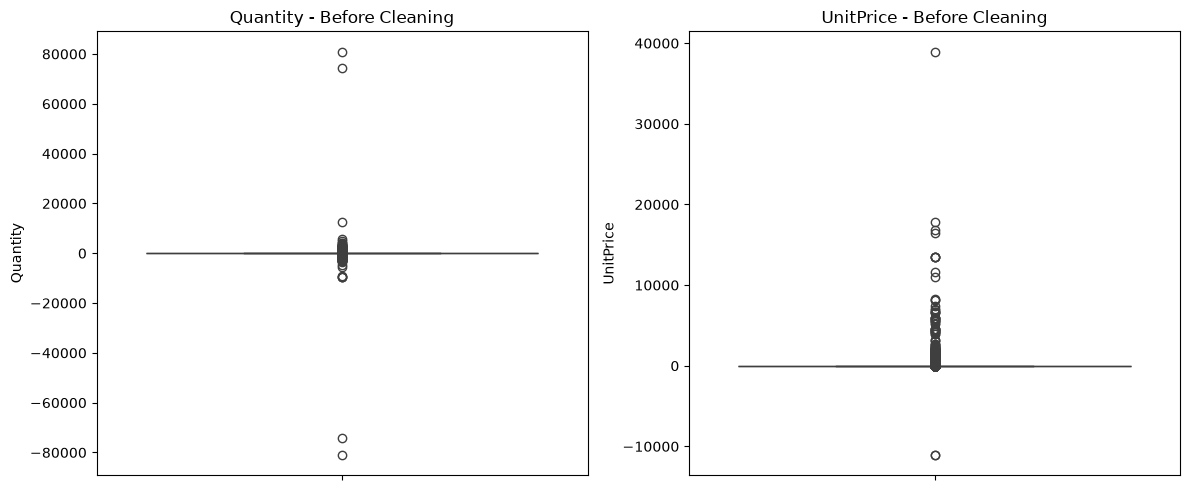

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Quantity"], ax=axes[0])
axes[0].set_title("Quantity - Before Cleaning")

sns.boxplot(y=df["UnitPrice"], ax=axes[1])
axes[1].set_title("UnitPrice - Before Cleaning")

plt.tight_layout()
plt.show()

In [14]:
# Step 10: Create a working copy and remove exact duplicates

df_clean = df.copy()

rows_before = len(df_clean)
duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicate rows from the working copy
df_clean = df_clean.drop_duplicates().copy()

rows_after = len(df_clean)
duplicates_after = df_clean.duplicated().sum()

print("Rows before cleaning:", rows_before)
print("Duplicate rows identified:", duplicates_before)
print("Rows after cleaning:", rows_after)
print("Remaining exact duplicates:", duplicates_after)
print("Original df rows (unchanged):", len(df))

Rows before cleaning: 541909
Duplicate rows identified: 5268
Rows after cleaning: 536641
Remaining exact duplicates: 0
Original df rows (unchanged): 541909


In [15]:
# Step 11: Handle missing product descriptions

# Count missing descriptions before cleaning
missing_before = df_clean["Description"].isna().sum()

# Create a mapping from StockCode to its most common
# non-missing product description
description_mapping = (
    df_clean.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
)

# Fill missing descriptions only when a matching StockCode
# has a known description
missing_mask = df_clean["Description"].isna()

df_clean.loc[missing_mask, "Description"] = (
    df_clean.loc[missing_mask, "StockCode"]
    .map(description_mapping)
)

missing_after = df_clean["Description"].isna().sum()

print("Missing descriptions before:", missing_before)
print("Missing descriptions after:", missing_after)
print(
    "Descriptions recovered:",
    missing_before - missing_after
)

Missing descriptions before: 1454
Missing descriptions after: 112
Descriptions recovered: 1342


In [16]:
# Step 12: Handle missing CustomerID values

missing_customer_before = df_clean["CustomerID"].isna().sum()

# Keep all transactions in df_clean.
# Create a separate dataset for customer-level analysis.
customer_analysis_df = df_clean.dropna(
    subset=["CustomerID"]
).copy()

missing_customer_after = df_clean["CustomerID"].isna().sum()

print("Missing CustomerID before:", missing_customer_before)
print("Missing CustomerID remaining in main dataset:", missing_customer_after)

print(
    "Rows available for customer-level analysis:",
    len(customer_analysis_df)
)

print(
    "Rows excluded from customer-level analysis:",
    len(df_clean) - len(customer_analysis_df)
)

Missing CustomerID before: 135037
Missing CustomerID remaining in main dataset: 135037
Rows available for customer-level analysis: 401604
Rows excluded from customer-level analysis: 135037


In [17]:
# Step 13: Investigate returns and unusual prices

# Check cancellation invoices
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)

cancellation_rows = df_clean[
    df_clean["InvoiceNo"].str.startswith("C")
]

# Check negative quantities
negative_quantity = df_clean[
    df_clean["Quantity"] < 0
]

# Check zero and negative prices
zero_price = df_clean[
    df_clean["UnitPrice"] == 0
]

negative_price = df_clean[
    df_clean["UnitPrice"] < 0
]

print("Cancellation invoice rows:", len(cancellation_rows))
print("Negative Quantity rows:", len(negative_quantity))
print("Zero UnitPrice rows:", len(zero_price))
print("Negative UnitPrice rows:", len(negative_price))

print("\nSample cancellation transactions:")
display(cancellation_rows.head(5))

print("\nSample negative price transactions:")
display(negative_price.head(5))

Cancellation invoice rows: 9251
Negative Quantity rows: 10587
Zero UnitPrice rows: 2510
Negative UnitPrice rows: 2

Sample cancellation transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom



Sample negative price transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [18]:
# Step 14: Feature Engineering

# Create a working copy
df_clean = df_clean.copy()

# 1. Calculate transaction revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# 2. Identify cancellation invoices
df_clean["Is_Cancellation"] = (
    df_clean["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

# 3. Identify negative quantity transactions
df_clean["Is_Return"] = df_clean["Quantity"] < 0

# 4. Extract date-related features
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

df_clean["InvoiceYear"] = df_clean["InvoiceDate"].dt.year
df_clean["InvoiceMonth"] = df_clean["InvoiceDate"].dt.month
df_clean["InvoiceDay"] = df_clean["InvoiceDate"].dt.day
df_clean["InvoiceWeekday"] = df_clean["InvoiceDate"].dt.day_name()

# 5. Show the results
display(
    df_clean[
        [
            "InvoiceNo",
            "InvoiceDate",
            "Quantity",
            "UnitPrice",
            "Revenue",
            "Is_Cancellation",
            "Is_Return",
            "InvoiceMonth",
            "InvoiceWeekday"
        ]
    ].head(10)
)

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue,Is_Cancellation,Is_Return,InvoiceMonth,InvoiceWeekday
0,536365,2010-12-01 08:26:00,6,2.55,15.30,False,False,12,Wednesday
1,536365,2010-12-01 08:26:00,6,3.39,20.34,False,False,12,Wednesday
2,536365,2010-12-01 08:26:00,8,2.75,22.00,False,False,12,Wednesday
3,536365,2010-12-01 08:26:00,6,3.39,20.34,False,False,12,Wednesday
4,536365,2010-12-01 08:26:00,6,3.39,20.34,False,False,12,Wednesday
5,536365,2010-12-01 08:26:00,2,7.65,15.30,False,False,12,Wednesday
6,536365,2010-12-01 08:26:00,6,4.25,25.50,False,False,12,Wednesday
7,536366,2010-12-01 08:28:00,6,1.85,11.10,False,False,12,Wednesday
8,536366,2010-12-01 08:28:00,6,1.85,11.10,False,False,12,Wednesday
9,536367,2010-12-01 08:34:00,32,1.69,54.08,False,False,12,Wednesday


In [19]:
# Step 15: Detect outliers using the IQR method

def detect_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]

    print(f"\nColumn: {column}")
    print("Q1:", q1)
    print("Q3:", q3)
    print("IQR:", iqr)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Potential outlier rows:", len(outliers))

    return outliers


# Positive values only for this outlier analysis
positive_quantity = df_clean[df_clean["Quantity"] > 0]
positive_price = df_clean[df_clean["UnitPrice"] > 0]

quantity_outliers = detect_outliers(
    positive_quantity, "Quantity"
)

price_outliers = detect_outliers(
    positive_price, "UnitPrice"
)


Column: Quantity
Q1: 1.0
Q3: 11.0
IQR: 10.0
Lower limit: -14.0
Upper limit: 26.0
Potential outlier rows: 27355

Column: UnitPrice
Q1: 1.25
Q3: 4.13
IQR: 2.88
Lower limit: -3.0700000000000003
Upper limit: 8.45
Potential outlier rows: 39448


In [20]:
from pathlib import Path

# Create output folder
output_dir = Path.cwd() / "Ouput"
output_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
cleaned_file = output_dir / "Online_Retail_Cleaned.csv"

df_clean.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", cleaned_file)
print("Final dataset shape:", df_clean.shape)

Cleaned dataset saved successfully!
File location: d:\Yuva Intern Tasks\Task 2\Ouput\Online_Retail_Cleaned.csv
Final dataset shape: (536641, 15)


In [21]:
import pandas as pd

quality_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Missing Values",
        "Duplicate Rows"
    ],
    "Before Cleaning": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],
    "After Cleaning": [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]
})

display(quality_report)

# Save report
quality_report.to_csv(
    output_dir / "Data_Quality_Before_After.csv",
    index=False
)

,Metric,Before Cleaning,After Cleaning
0,Total Rows,541909,536641
1,Total Columns,8,15
2,Missing Values,136534,135149
3,Duplicate Rows,5268,0


In [23]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Use valid positive values for this demonstration
scaling_data = df_clean[["Quantity", "UnitPrice"]].copy()

scaling_data = scaling_data[
    (scaling_data["Quantity"] > 0) &
    (scaling_data["UnitPrice"] > 0)
].dropna()

# Standardization: mean approximately 0, standard deviation approximately 1
standard_scaler = StandardScaler()

scaling_data["Quantity_Standardized"] = (
    standard_scaler.fit_transform(
        scaling_data[["Quantity"]]
    ).ravel()
)

# Normalization: values between 0 and 1
minmax_scaler = MinMaxScaler()

scaling_data["UnitPrice_Normalized"] = (
    minmax_scaler.fit_transform(
        scaling_data[["UnitPrice"]]
    ).ravel()
)

display(scaling_data.head(10))

print("Rows used:", len(scaling_data))
print("Normalized UnitPrice minimum:",
      scaling_data["UnitPrice_Normalized"].min())
print("Normalized UnitPrice maximum:",
      scaling_data["UnitPrice_Normalized"].max())

,Quantity,UnitPrice,Quantity_Standardized,UnitPrice_Normalized
0,6,2.55,-0.029541,0.000188
1,6,3.39,-0.029541,0.000250
2,8,2.75,-0.016743,0.000203
3,6,3.39,-0.029541,0.000250
4,6,3.39,-0.029541,0.000250
5,2,7.65,-0.055136,0.000565
6,6,4.25,-0.029541,0.000314
7,6,1.85,-0.029541,0.000137
8,6,1.85,-0.029541,0.000137
9,32,1.69,0.136828,0.000125


Rows used: 524878
Normalized UnitPrice minimum: 0.0
Normalized UnitPrice maximum: 1.0


In [24]:
# Step 18: Categorical Encoding

# Select a small sample to demonstrate encoding
country_sample = df_clean[["Country"]].dropna().head(10).copy()

# Apply One-Hot Encoding
country_encoded = pd.get_dummies(
    country_sample,
    columns=["Country"],
    dtype=int
)

print("Original Country Data:")
display(country_sample)

print("Encoded Country Data:")
display(country_encoded)

Original Country Data:


,Country
0,United Kingdom
1,United Kingdom
2,United Kingdom
3,United Kingdom
4,United Kingdom
5,United Kingdom
6,United Kingdom
7,United Kingdom
8,United Kingdom
9,United Kingdom


Encoded Country Data:


,Country_United Kingdom
0,1
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


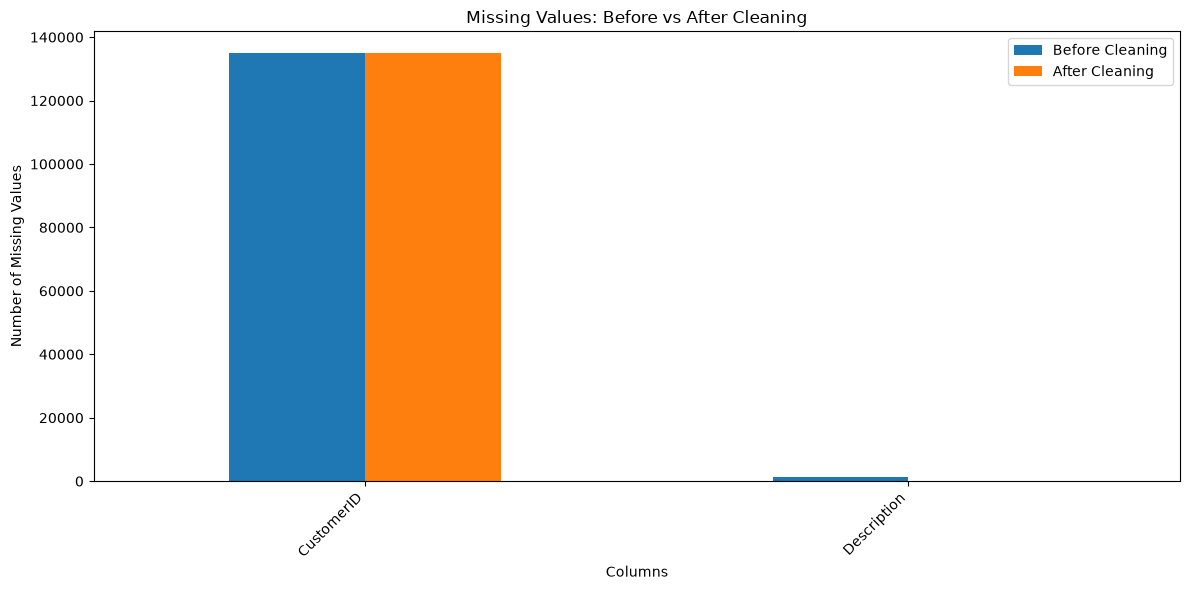

Chart saved at: d:\Yuva Intern Tasks\Task 2\Ouput\Missing_Values_Comparison.png


In [25]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create output folder
output_dir = Path.cwd() / "Ouput"
output_dir.mkdir(parents=True, exist_ok=True)

# Compare missing values before and after cleaning
missing_comparison = pd.DataFrame({
    "Before Cleaning": df.isnull().sum(),
    "After Cleaning": df_clean.isnull().sum()
})

missing_comparison = missing_comparison[
    missing_comparison.sum(axis=1) > 0
]

ax = missing_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Missing Values: Before vs After Cleaning")
ax.set_xlabel("Columns")
ax.set_ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save chart
plt.savefig(
    output_dir / "Missing_Values_Comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Chart saved at:", output_dir / "Missing_Values_Comparison.png")

In [26]:
# Step 20: Final Data Cleaning Summary

summary = {
    "Metric": [
        "Original Rows",
        "Final Rows",
        "Rows Removed",
        "Original Columns",
        "Final Columns",
        "Duplicates Before Cleaning",
        "Duplicates After Cleaning",
        "Missing Values Before Cleaning",
        "Missing Values After Cleaning",
        "Missing CustomerID After Cleaning",
        "Missing Description After Cleaning",
        "Negative Quantity Rows",
        "Zero or Negative UnitPrice Rows"
    ],
    "Value": [
        len(df),
        len(df_clean),
        len(df) - len(df_clean),
        len(df.columns),
        len(df_clean.columns),
        df.duplicated().sum(),
        df_clean.duplicated().sum(),
        df.isnull().sum().sum(),
        df_clean.isnull().sum().sum(),
        df_clean["CustomerID"].isnull().sum(),
        df_clean["Description"].isnull().sum(),
        (df_clean["Quantity"] < 0).sum(),
        (df_clean["UnitPrice"] <= 0).sum()
    ]
}

summary_df = pd.DataFrame(summary)

display(summary_df)

# Save summary
summary_path = output_dir / "Final_Data_Cleaning_Summary.csv"
summary_df.to_csv(summary_path, index=False)

print("Summary saved at:", summary_path)

,Metric,Value
0,Original Rows,541909
1,Final Rows,536641
2,Rows Removed,5268
3,Original Columns,8
4,Final Columns,15
5,Duplicates Before Cleaning,5268
6,Duplicates After Cleaning,0
7,Missing Values Before Cleaning,136534
8,Missing Values After Cleaning,135149
9,Missing CustomerID After Cleaning,135037


Summary saved at: d:\Yuva Intern Tasks\Task 2\Ouput\Final_Data_Cleaning_Summary.csv


In [27]:
%pip install python-docx

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   ------------ --------------------------- 1.3/4.1 MB 9.8 MB/s eta 0:00:01
   ------------------------------ --------- 3.1/4.1 MB 8.3 MB/s eta 0:00:01
   -------------------------------------- - 3.9/4.1 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------- 4.1/4.1 MB 5.3 MB/s  0:00:00

   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   ------------------

In [28]:
from pathlib import Path

output_dir = Path.cwd() / "Ouput"
output_dir.mkdir(parents=True, exist_ok=True)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicate rows remaining:", df_clean.duplicated().sum())
print("Missing values remaining:", df_clean.isnull().sum().sum())
print("Output folder:", output_dir)
print("Saved files:")

for file in output_dir.iterdir():
    print("-", file.name)

Original dataset shape: (541909, 8)
Cleaned dataset shape: (536641, 15)
Duplicate rows remaining: 0
Missing values remaining: 135149
Output folder: d:\Yuva Intern Tasks\Task 2\Ouput
Saved files:
- Data_Quality_Before_After.csv
- Final_Data_Cleaning_Summary.csv
- Missing_Values_Comparison.png
- Online_Retail_Cleaned.csv


In [30]:
from docx import Document
from docx.shared import Inches, Pt
from pathlib import Path
import pandas as pd

# Output folder
output_dir = Path.cwd() / "Ouput"
output_dir.mkdir(parents=True, exist_ok=True)

# Create Word document
doc = Document()

doc.add_heading("Data Cleaning and Pre-Processing", 0)
doc.add_paragraph("YuvaIntern – Data Analytics Internship")
doc.add_paragraph("Dataset: UCI Online Retail Dataset")
doc.add_paragraph("Tools: Python, Pandas, NumPy, Matplotlib, Scikit-learn")

doc.add_heading("1. Project Objective", level=1)
doc.add_paragraph(
    "The objective of this project is to inspect, clean and preprocess "
    "retail transaction data. The work includes identifying missing values, "
    "removing exact duplicates, investigating unusual values, engineering "
    "features, and demonstrating scaling and categorical encoding."
)

doc.add_heading("2. Initial Data Quality Assessment", level=1)
doc.add_paragraph(f"Original rows: {len(df):,}")
doc.add_paragraph(f"Original columns: {len(df.columns)}")
doc.add_paragraph(f"Missing values before cleaning: {df.isnull().sum().sum():,}")
doc.add_paragraph(f"Duplicate rows before cleaning: {df.duplicated().sum():,}")

doc.add_heading("3. Data Cleaning Methods", level=1)
doc.add_paragraph(
    "Exact duplicate rows were removed from a working copy of the dataset. "
    "Missing product descriptions were filled where a description could be "
    "mapped from the same StockCode. CustomerID values were not guessed or "
    "artificially imputed; records without CustomerID can be excluded from "
    "customer-specific analysis."
)

doc.add_heading("4. Outlier and Transaction Checks", level=1)
doc.add_paragraph(
    "Quantity and UnitPrice were investigated using the IQR method. "
    "Negative quantities may represent returns, and invoices beginning "
    "with 'C' may represent cancellations. Such records were not "
    "automatically deleted because they may contain meaningful business data."
)

doc.add_heading("5. Feature Engineering", level=1)
doc.add_paragraph(
    "New features include Revenue (Quantity multiplied by UnitPrice), "
    "Is_Cancellation, Is_Return, InvoiceYear, InvoiceMonth, InvoiceDay, "
    "and InvoiceWeekday."
)

doc.add_heading("6. Scaling, Normalization and Encoding", level=1)
doc.add_paragraph(
    "StandardScaler was demonstrated on positive Quantity values, while "
    "MinMaxScaler was demonstrated on positive UnitPrice values. One-hot "
    "encoding was demonstrated on a small sample of the Country column. "
    "These demonstrations did not overwrite the original cleaned dataset."
)

doc.add_heading("7. Final Data Quality Results", level=1)
doc.add_paragraph(f"Rows after cleaning: {len(df_clean):,}")
doc.add_paragraph(f"Columns after cleaning: {len(df_clean.columns)}")
doc.add_paragraph(f"Duplicate rows remaining: {df_clean.duplicated().sum():,}")
doc.add_paragraph(f"Missing values remaining: {df_clean.isnull().sum().sum():,}")
doc.add_paragraph(
    f"Missing CustomerID values remaining: "
    f"{df_clean['CustomerID'].isnull().sum():,}"
)
doc.add_paragraph(
    f"Missing Description values remaining: "
    f"{df_clean['Description'].isnull().sum():,}"
)

doc.add_heading("8. Limitations and Further Improvements", level=1)
doc.add_paragraph(
    "Missing CustomerID values remain unresolved because assigning invented "
    "customer identifiers would reduce data reliability. Outlier thresholds "
    "identify unusual values but do not prove that those values are errors. "
    "Further validation with business rules is recommended before excluding "
    "transactions."
)

doc.add_heading("9. Conclusion", level=1)
doc.add_paragraph(
    "The project established a repeatable preprocessing workflow for retail "
    "transaction data. It addressed duplicate records, reviewed missing "
    "values and unusual transactions, created analytical features, and "
    "demonstrated scaling and encoding methods."
)

report_path = output_dir / "YuvaIntern_Week2_Data_Cleaning_Report.docx"
doc.save(report_path)

print("Word report created successfully!")
print("Report location:", report_path)

Word report created successfully!
Report location: d:\Yuva Intern Tasks\Task 2\Ouput\YuvaIntern_Week2_Data_Cleaning_Report.docx
